# GDM Dataset — Exploratory Data Analysis
**Source:** St. Mary's Hospital, London — Figshare  
**Records:** 23,490 pregnancies (April 2016 – March 2019)

In [1]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style='whitegrid', palette='muted', font_scale=1.05)
plt.rcParams['figure.dpi'] = 120

# Works whether Jupyter is started from project root or notebooks/
for candidate in [Path('../data/raw/gdm_dataset.csv'), Path('data/raw/gdm_dataset.csv')]:
    if candidate.exists():
        DATA_PATH = candidate
        break

df_raw = pd.read_csv(DATA_PATH, low_memory=False)
print(f'Loaded: {DATA_PATH}  |  Shape: {df_raw.shape}')
df_raw.head(3)

Loaded: ..\data\raw\gdm_dataset.csv  |  Shape: (23490, 48)


,UID,Index of Multiple Deprivation Rank,IMD Decile,AgeAtStartOfSpell,WeightMeasured,Height,Body Mass Index at Booking,Obese?,Ethnicity,Risk Factors,...,BW Centile,Shoulder Dystocia,SCBU admission (Yes/NO),LOS mother after delivery,Sex,Still_Birth,TotalApgarScoreat1minutes,APGAR_Score_5,TotalApgarScoreat10minutes,Maternity_Month
0,1,20324,7,30,101.008592,178.0,31.88,Yes,GBR,NaN,...,44.8,No,No,5,Female,NO,5.0,8.0,10.0,2016/04
1,2,19260,6,29,91.014089,173.0,30.41,Yes,OTH,NaN,...,19.7,No,No,3,Male,NO,9.0,10.0,10.0,2017/02
2,3,5627,2,22,65.395008,168.0,23.17,No,GBR,NaN,...,75.8,No,No,0,Female,NO,NaN,NaN,NaN,2018/05


## 1. Data Prep
Convert glucose columns (read as strings due to NULLs) to numeric.

In [2]:
df = df_raw.copy()

# Glucose columns stored as strings → numeric
for col in ['Glucoselevel0minblood', 'Glucoselevel120minblood', 'Glucoselevelblood', 'VitaminDlevelblood']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Binary targets
df['GDM'] = df['Gestational Diabetes'].str.strip().map({'Yes': 1, 'No': 0})
df['SCBU'] = df['SCBU admission (Yes/NO)'].str.strip().map({'Yes': 1, 'No': 0})

# Core numeric columns for EDA
NUM_COLS = [
    'AgeAtStartOfSpell', 'WeightMeasured', 'Height', 'Body Mass Index at Booking',
    'Glucoselevel0minblood', 'Glucoselevel120minblood',
    'SystolicBloodPressureCuff', 'Diastolic Blood Pressure',
    'Gestation', 'BabyBirthWeight', 'BW Centile',
    'EstimatedTotalBloodLoss', 'LOS mother after delivery',
    'TotalApgarScoreat1minutes', 'APGAR_Score_5', 'TotalApgarScoreat10minutes'
]

LABELS = {
    'AgeAtStartOfSpell': 'Age (years)',
    'WeightMeasured': 'Weight (kg)',
    'Height': 'Height (cm)',
    'Body Mass Index at Booking': 'BMI at Booking',
    'Glucoselevel0minblood': 'OGTT 0-min Glucose (mmol/L)',
    'Glucoselevel120minblood': 'OGTT 120-min Glucose (mmol/L)',
    'SystolicBloodPressureCuff': 'Systolic BP (mmHg)',
    'Diastolic Blood Pressure': 'Diastolic BP (mmHg)',
    'Gestation': 'Gestation (weeks)',
    'BabyBirthWeight': 'Birth Weight (g)',
    'BW Centile': 'Birth Weight Centile',
    'EstimatedTotalBloodLoss': 'Estimated Blood Loss (mL)',
    'LOS mother after delivery': 'Length of Stay (days)',
    'TotalApgarScoreat1minutes': 'APGAR @ 1 min',
    'APGAR_Score_5': 'APGAR @ 5 min',
    'TotalApgarScoreat10minutes': 'APGAR @ 10 min'
}

print('GDM prevalence:', df['GDM'].value_counts().to_dict())
print('SCBU prevalence:', df['SCBU'].value_counts().to_dict())

GDM prevalence: {0: 21636, 1: 1854}
SCBU prevalence: {0: 22195, 1: 1295}


## 2. Missing Values Overview

In [3]:
missing = (
    df[NUM_COLS].isnull().sum()
    .rename('missing')
    .to_frame()
)
missing['pct'] = (missing['missing'] / len(df) * 100).round(1)
missing.sort_values('pct', ascending=False)

,missing,pct
Diastolic Blood Pressure,15346,65.3
SystolicBloodPressureCuff,13828,58.9
Glucoselevel120minblood,6623,28.2
Glucoselevel0minblood,6581,28.0
TotalApgarScoreat10minutes,3961,16.9
APGAR_Score_5,2203,9.4
TotalApgarScoreat1minutes,2129,9.1
EstimatedTotalBloodLoss,115,0.5
AgeAtStartOfSpell,0,0.0
WeightMeasured,0,0.0


## 3. Mean & Median Summary

In [4]:
stats = df[NUM_COLS].agg(['count', 'mean', 'median', 'std', 'min', 'max']).T
stats.index = [LABELS.get(c, c) for c in stats.index]
stats = stats.round(2)
stats.columns = ['N (non-null)', 'Mean', 'Median', 'Std Dev', 'Min', 'Max']

# Highlight mean vs median gap
stats['Mean-Median Gap'] = (stats['Mean'] - stats['Median']).round(2)
stats

,N (non-null),Mean,Median,Std Dev,Min,Max,Mean-Median Gap
Age (years),23490.0,32.04,32.00,5.53,14.00,53.00,0.04
Weight (kg),23490.0,68.24,65.41,14.66,33.59,167.00,2.83
Height (cm),23490.0,163.78,164.00,6.87,103.00,195.00,-0.22
BMI at Booking,23490.0,25.44,24.35,5.22,14.19,69.51,1.09
OGTT 0-min Glucose (mmol/L),16909.0,4.35,4.30,0.52,2.00,13.30,0.05
OGTT 120-min Glucose (mmol/L),16867.0,5.84,5.70,1.54,1.70,24.50,0.14
Systolic BP (mmHg),9662.0,113.20,112.00,13.09,11.00,186.00,1.20
Diastolic BP (mmHg),8144.0,68.12,68.00,9.45,0.00,110.00,0.12
Gestation (weeks),23490.0,38.97,39.00,1.99,24.00,43.00,-0.03
Birth Weight (g),23490.0,3275.02,3300.00,573.54,150.00,5500.00,-24.98


## 4. Histograms — All Numeric Features

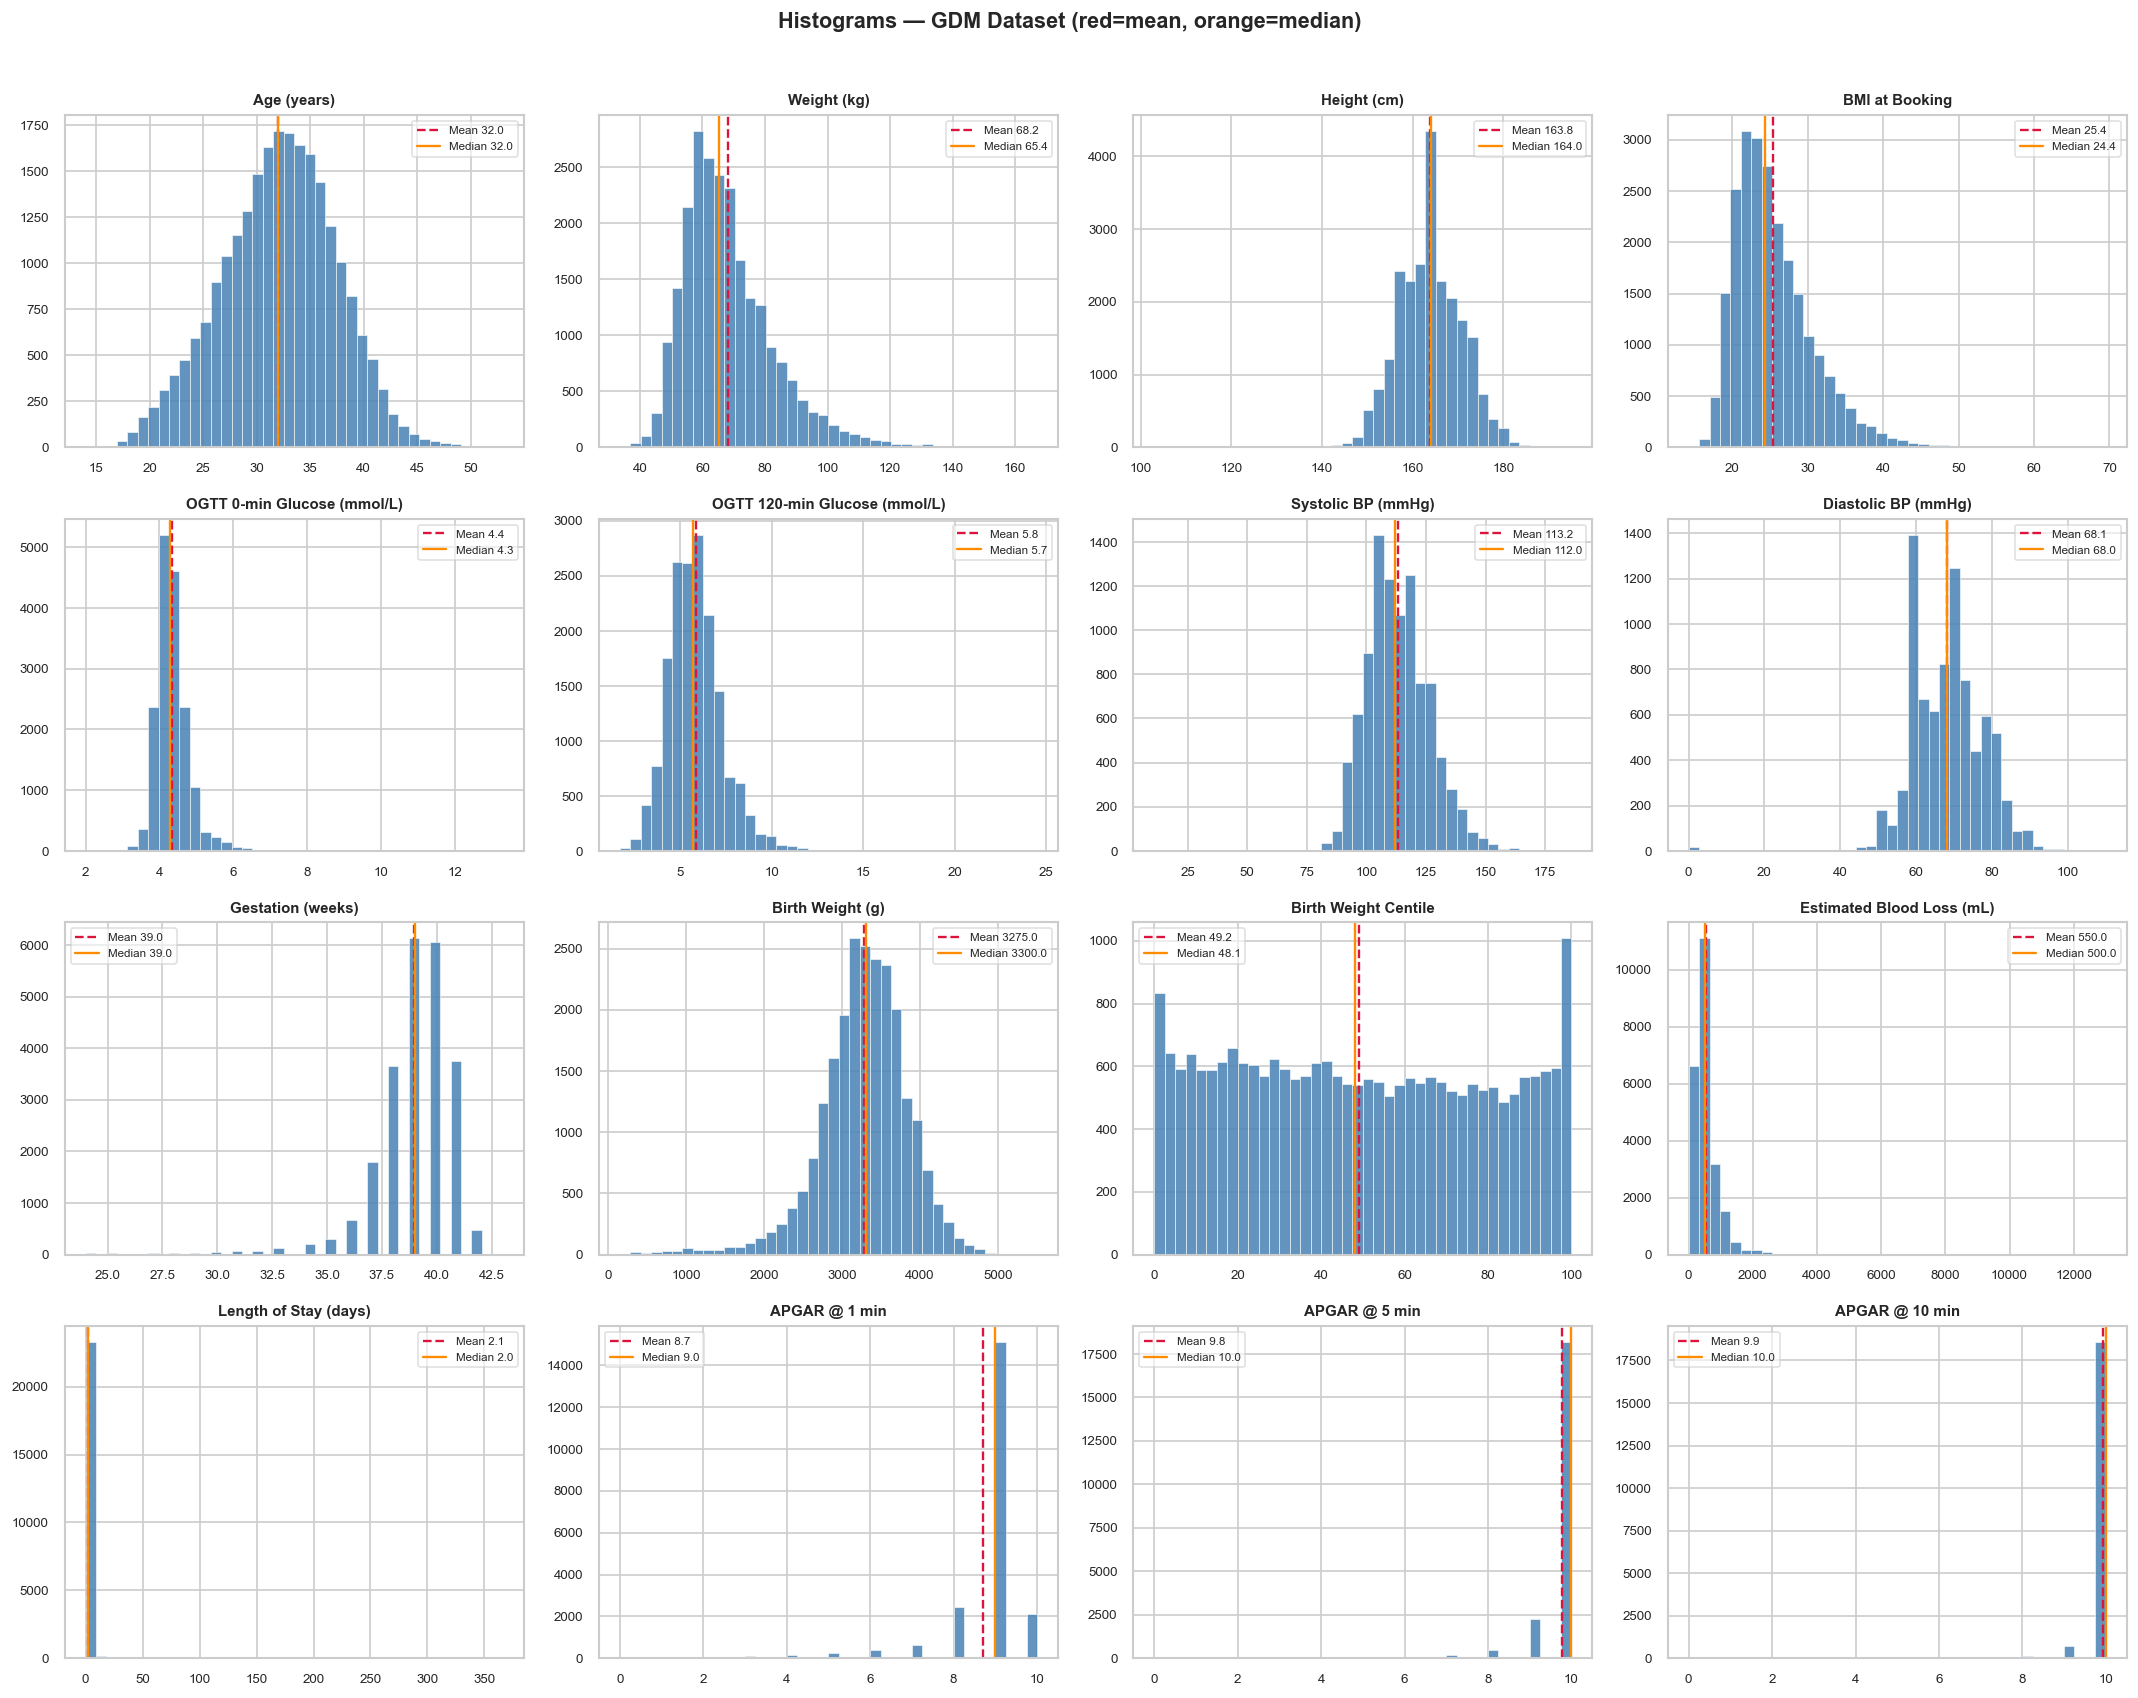

In [5]:
n = len(NUM_COLS)
ncols = 4
nrows = -(-n // ncols)  # ceil

fig, axes = plt.subplots(nrows, ncols, figsize=(18, nrows * 3.5))
axes = axes.flatten()

for i, col in enumerate(NUM_COLS):
    ax = axes[i]
    data = df[col].dropna()
    ax.hist(data, bins=40, color='steelblue', edgecolor='white', linewidth=0.4, alpha=0.85)
    ax.axvline(data.mean(),   color='crimson',     linestyle='--', linewidth=1.4, label=f'Mean {data.mean():.1f}')
    ax.axvline(data.median(), color='darkorange',  linestyle='-',  linewidth=1.4, label=f'Median {data.median():.1f}')
    ax.set_title(LABELS.get(col, col), fontsize=9, fontweight='bold')
    ax.set_xlabel('')
    ax.legend(fontsize=7, framealpha=0.6)
    ax.tick_params(labelsize=8)

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

fig.suptitle('Histograms — GDM Dataset (red=mean, orange=median)', fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

## 5. Density Plots (KDE) — Overlay by GDM Status

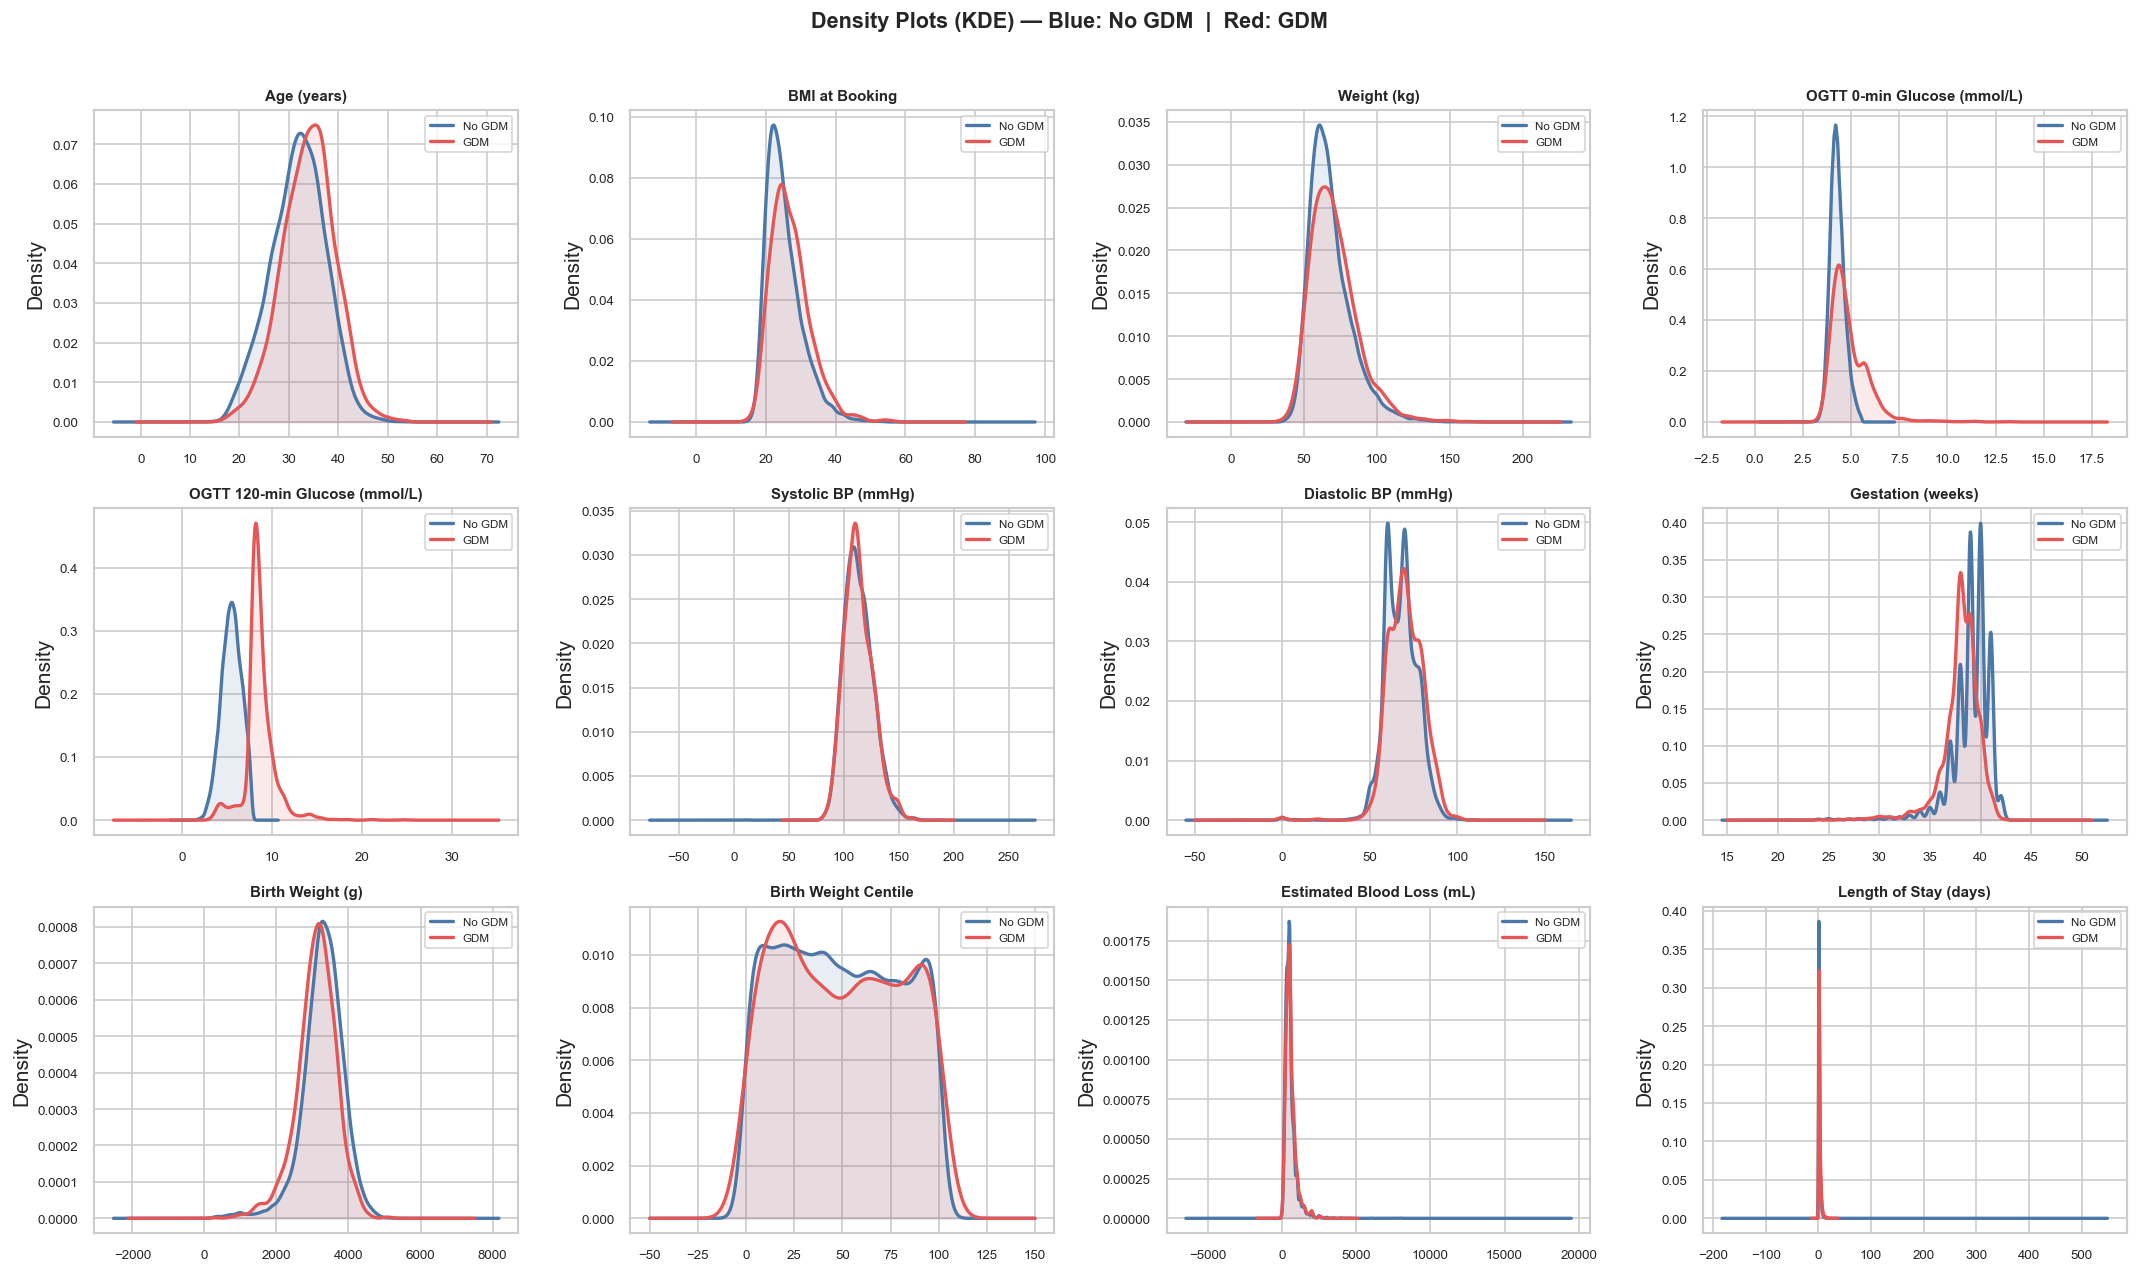

In [6]:
# Columns where GDM split is clinically interesting
KDE_COLS = [
    'AgeAtStartOfSpell', 'Body Mass Index at Booking', 'WeightMeasured',
    'Glucoselevel0minblood', 'Glucoselevel120minblood',
    'SystolicBloodPressureCuff', 'Diastolic Blood Pressure',
    'Gestation', 'BabyBirthWeight', 'BW Centile',
    'EstimatedTotalBloodLoss', 'LOS mother after delivery'
]

ncols = 4
nrows = -(-len(KDE_COLS) // ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(18, nrows * 3.5))
axes = axes.flatten()

palette = {0: '#4c78a8', 1: '#e45756'}
gdm_df = df.dropna(subset=['GDM'])

for i, col in enumerate(KDE_COLS):
    ax = axes[i]
    for gdm_val, label, color in [(0, 'No GDM', '#4c78a8'), (1, 'GDM', '#e45756')]:
        subset = gdm_df.loc[gdm_df['GDM'] == gdm_val, col].dropna()
        if len(subset) > 10:
            subset.plot.kde(ax=ax, label=label, color=color, linewidth=2)
            ax.fill_between(
                *[d for d in [ax.lines[-1].get_xdata(), ax.lines[-1].get_ydata()]],
                alpha=0.12, color=color
            )
    ax.set_title(LABELS.get(col, col), fontsize=9, fontweight='bold')
    ax.set_xlabel('')
    ax.legend(fontsize=7)
    ax.tick_params(labelsize=8)

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

fig.suptitle('Density Plots (KDE) — Blue: No GDM  |  Red: GDM', fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

## 6. Box Plots — Distribution + Outliers by GDM Status

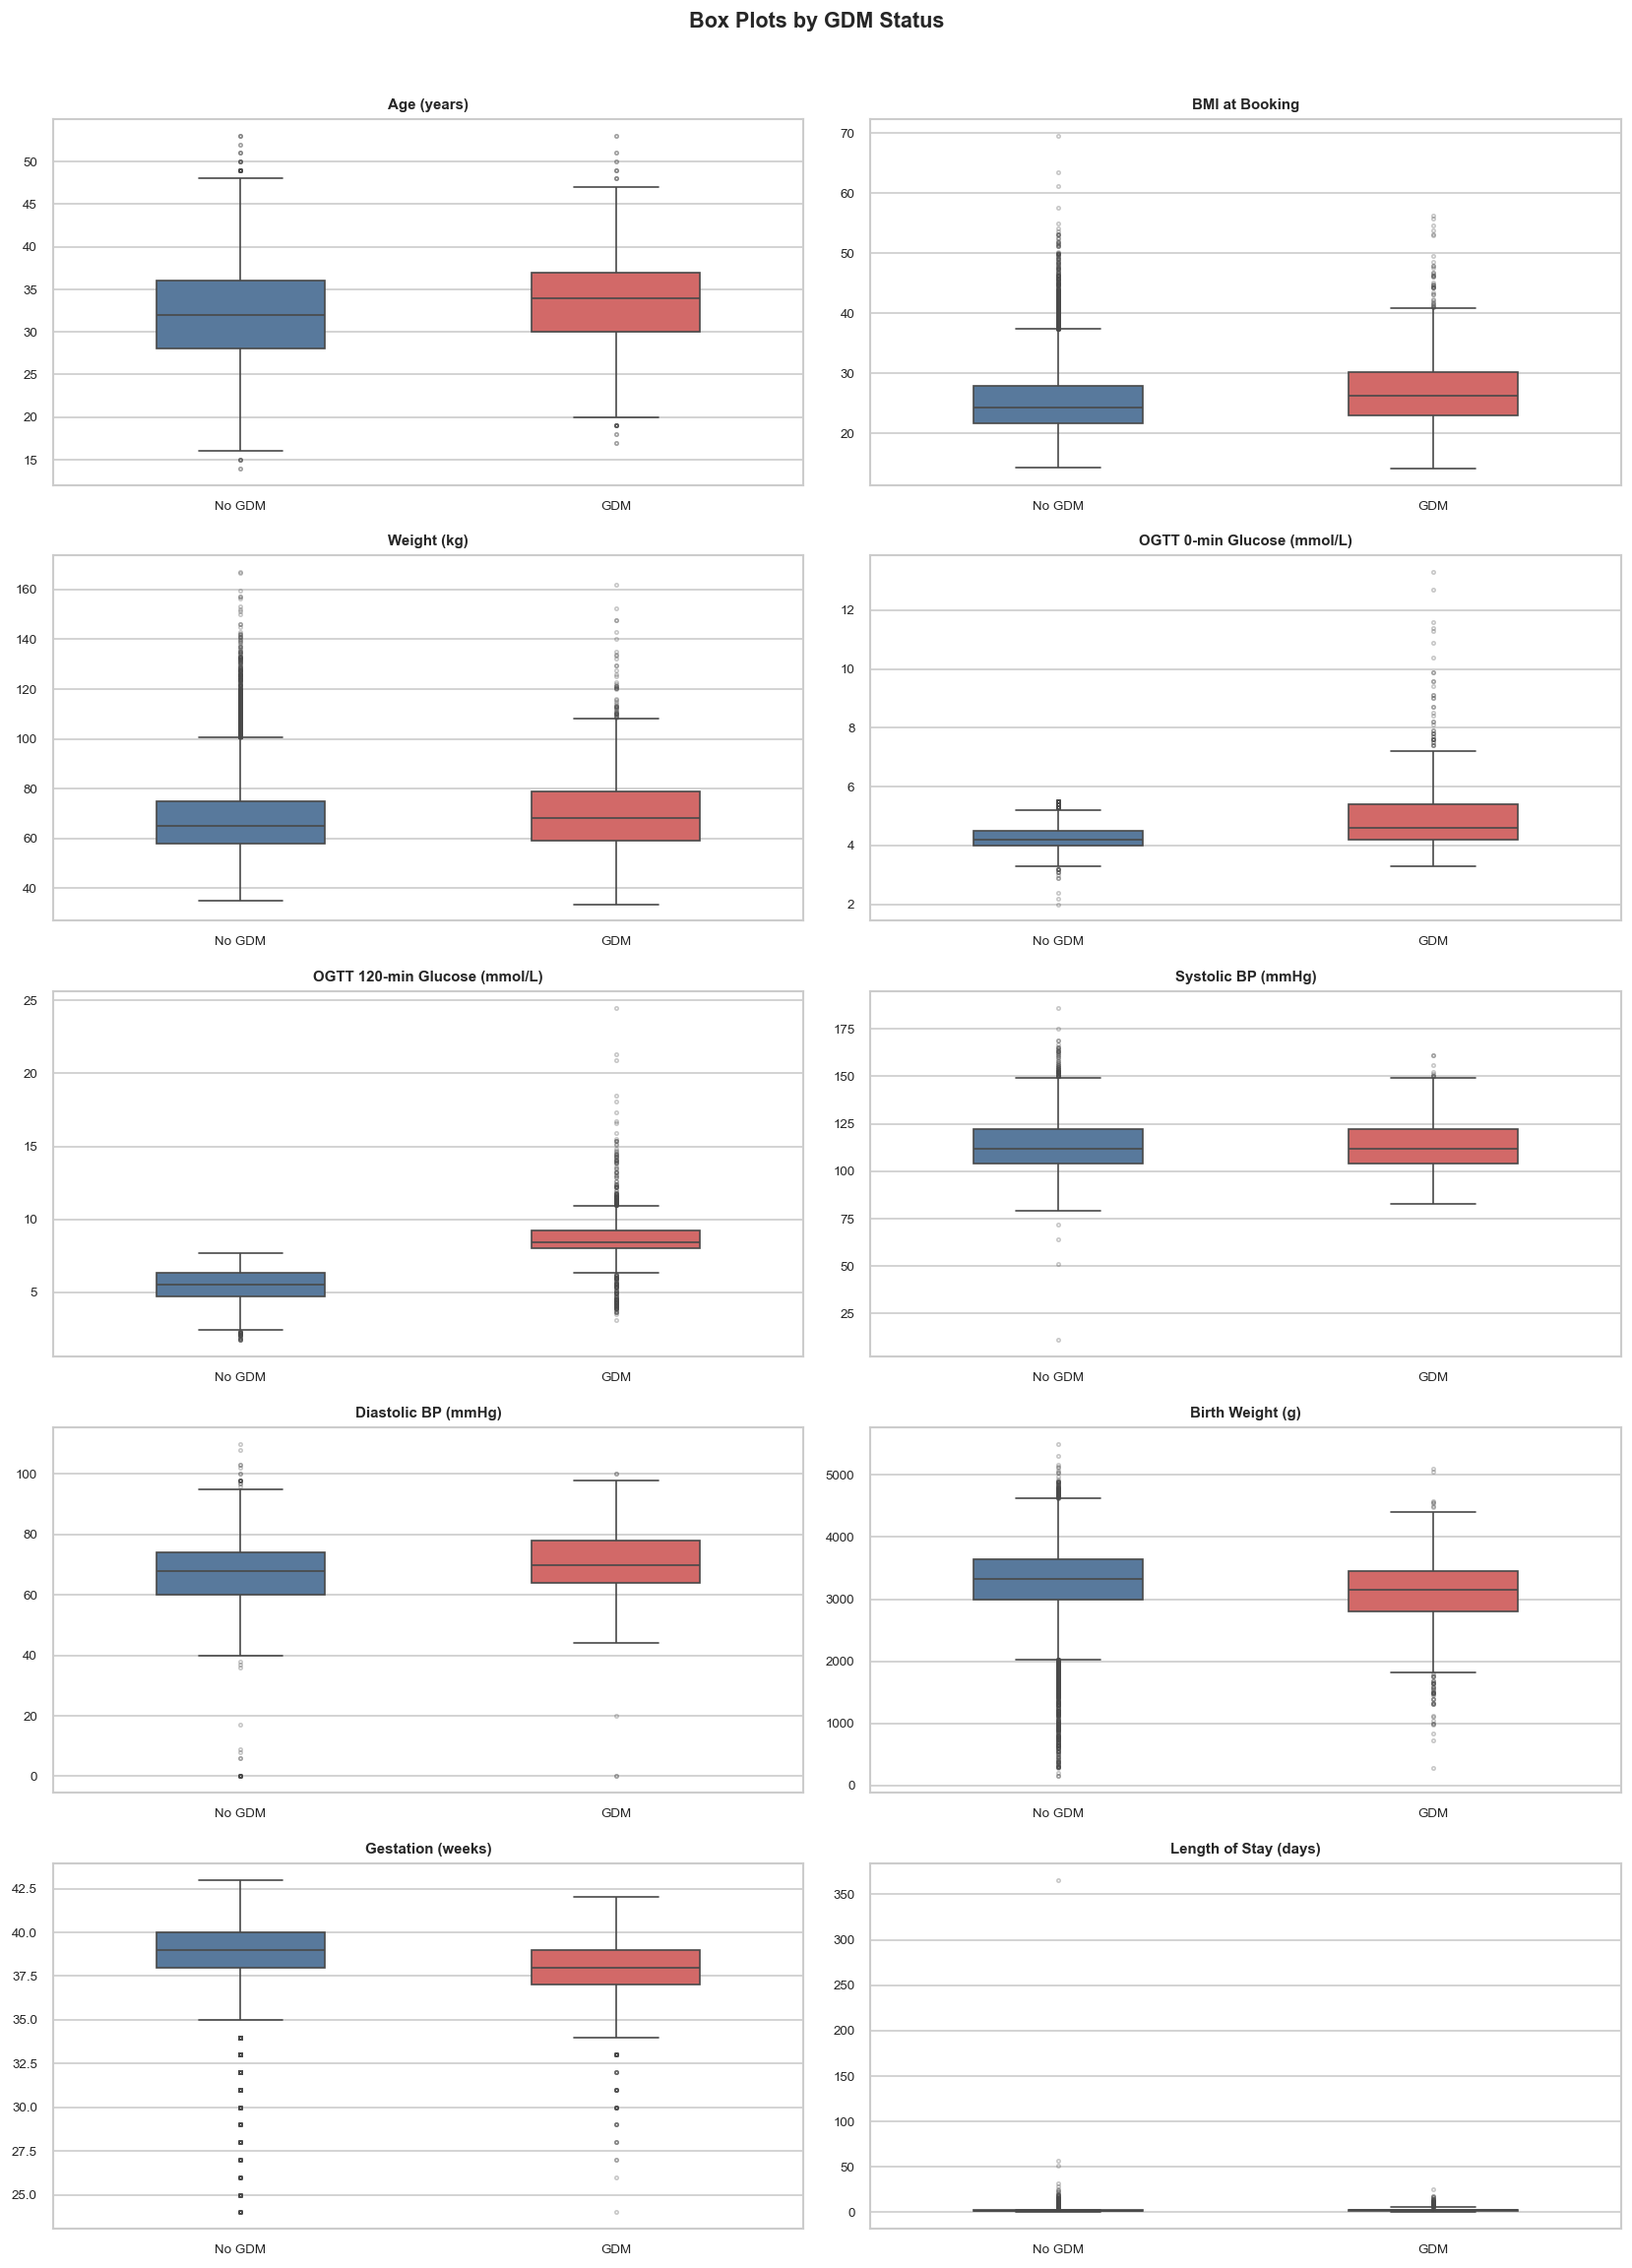

In [7]:
BOX_COLS = [
    'AgeAtStartOfSpell', 'Body Mass Index at Booking', 'WeightMeasured',
    'Glucoselevel0minblood', 'Glucoselevel120minblood',
    'SystolicBloodPressureCuff', 'Diastolic Blood Pressure',
    'BabyBirthWeight', 'Gestation', 'LOS mother after delivery'
]

ncols = 2
nrows = -(-len(BOX_COLS) // ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(14, nrows * 3.8))
axes = axes.flatten()

for i, col in enumerate(BOX_COLS):
    ax = axes[i]
    plot_df = gdm_df[['GDM', col]].dropna()
    plot_df['GDM Label'] = plot_df['GDM'].map({0: 'No GDM', 1: 'GDM'})
    sns.boxplot(
        data=plot_df, x='GDM Label', y=col, ax=ax,
        palette={'No GDM': '#4c78a8', 'GDM': '#e45756'},
        width=0.45, flierprops=dict(marker='o', markersize=2, alpha=0.3),
        order=['No GDM', 'GDM']
    )
    ax.set_title(LABELS.get(col, col), fontsize=9, fontweight='bold')
    ax.set_xlabel('')
    ax.set_ylabel('')
    ax.tick_params(labelsize=8)

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

fig.suptitle('Box Plots by GDM Status', fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

## 7. Scatter Plots — Key Clinical Relationships

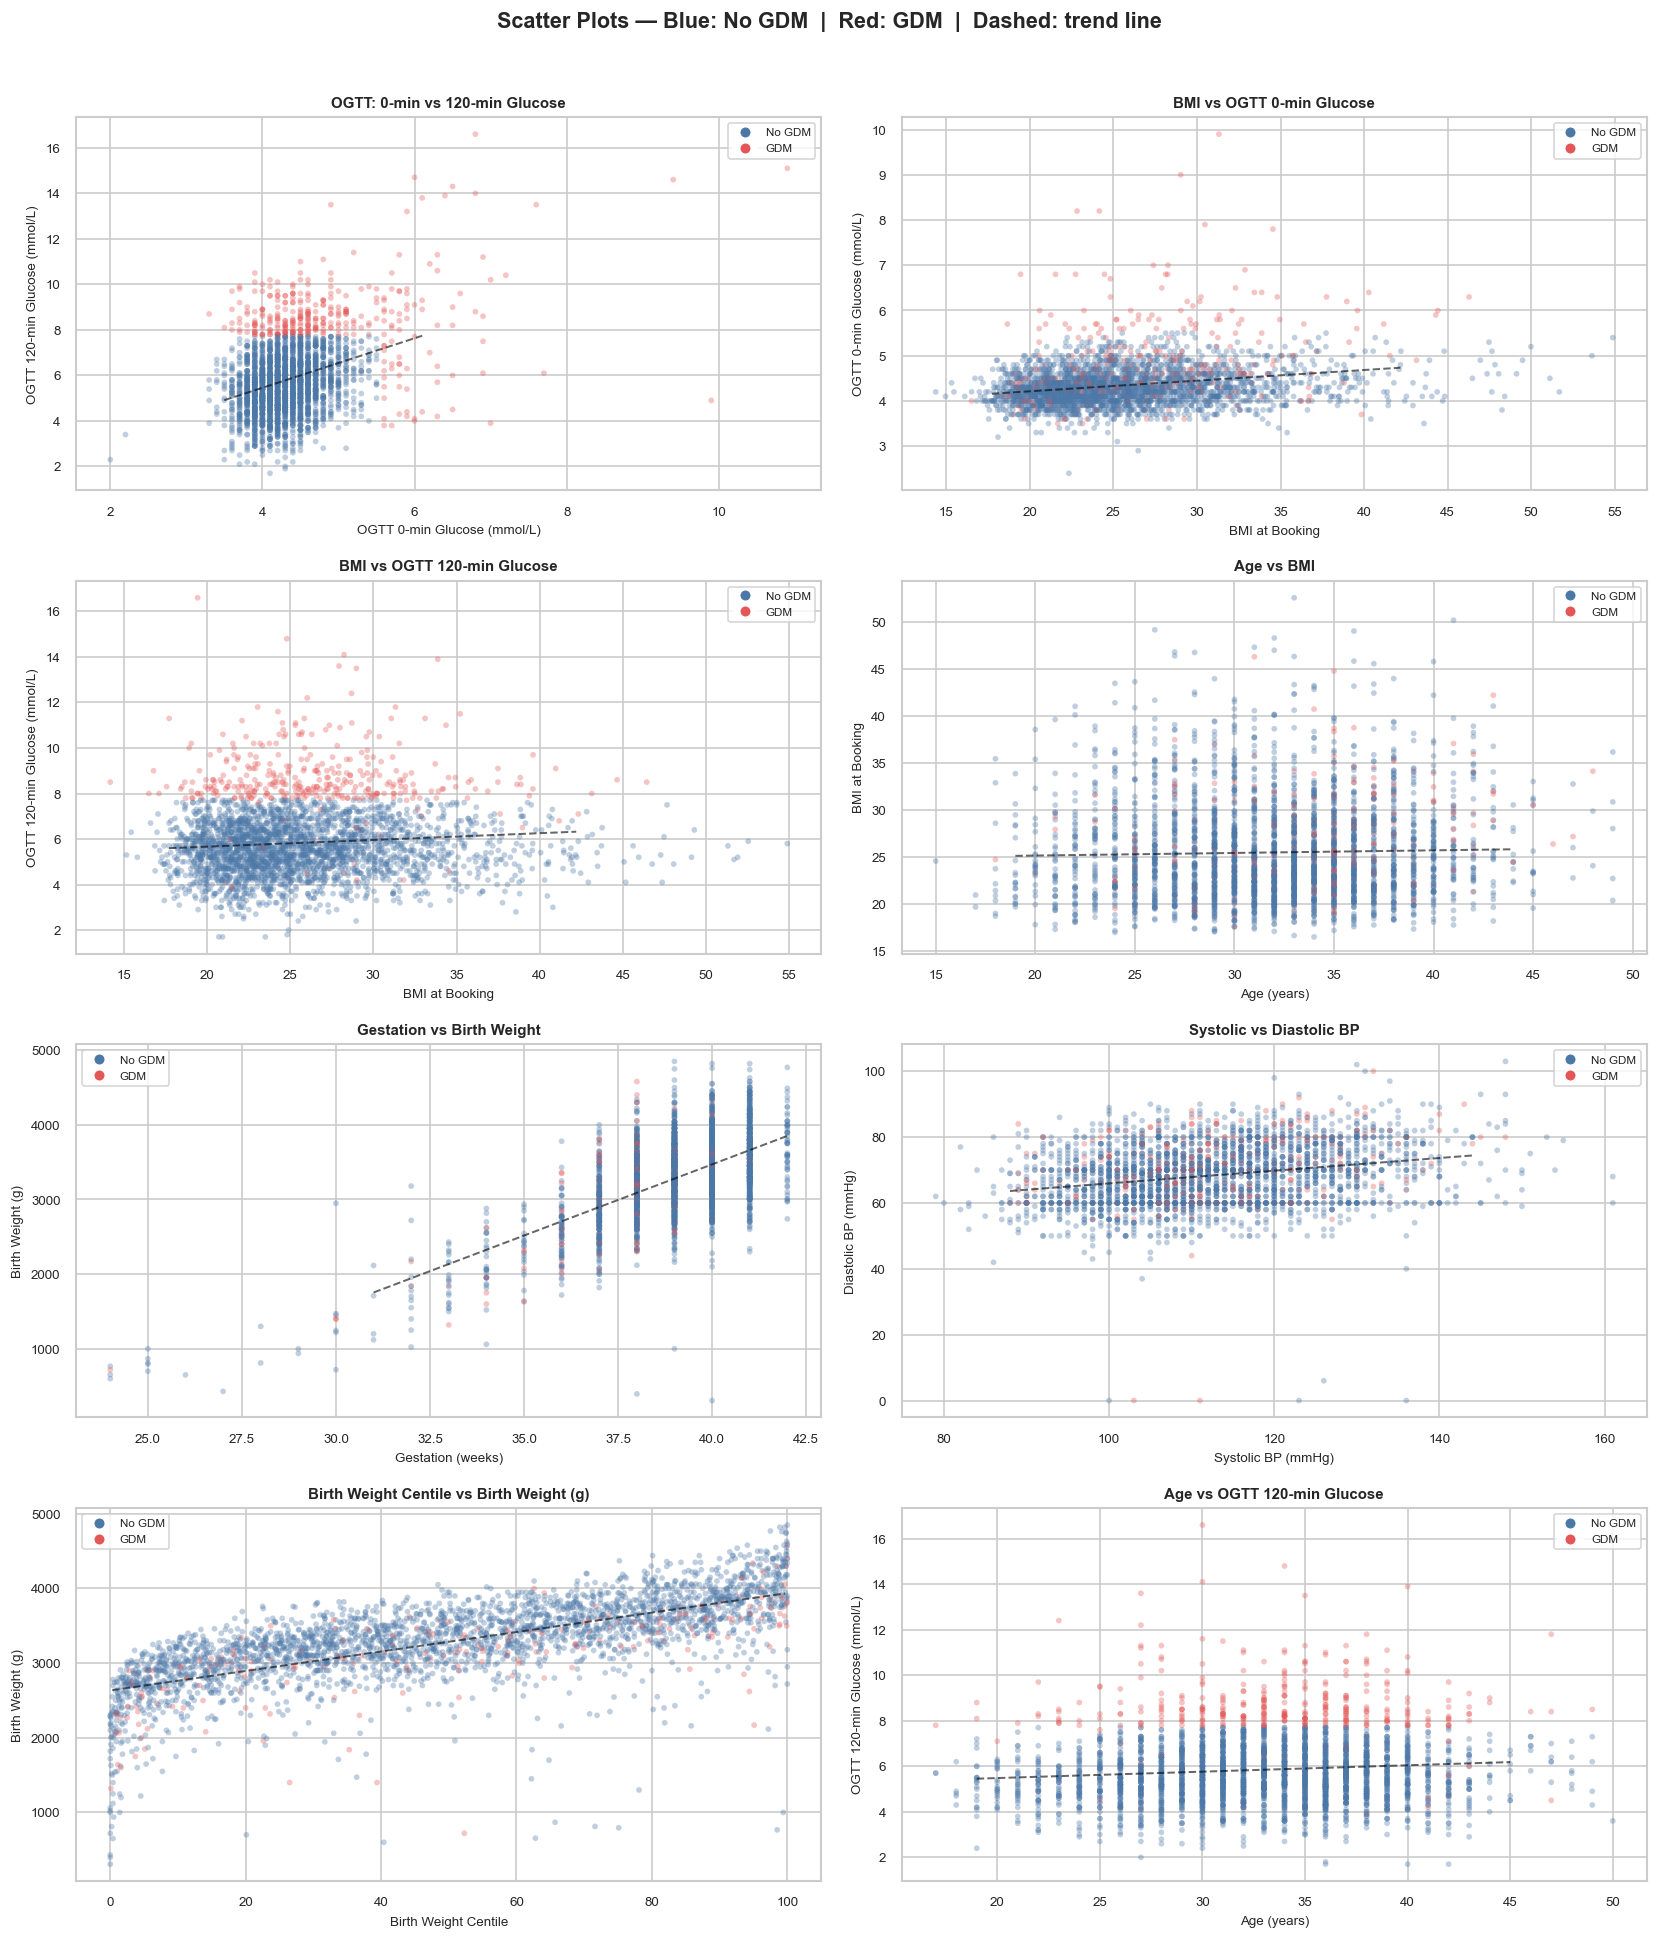

In [8]:
SCATTER_PAIRS = [
    ('Glucoselevel0minblood',     'Glucoselevel120minblood',    'OGTT: 0-min vs 120-min Glucose'),
    ('Body Mass Index at Booking','Glucoselevel0minblood',      'BMI vs OGTT 0-min Glucose'),
    ('Body Mass Index at Booking','Glucoselevel120minblood',    'BMI vs OGTT 120-min Glucose'),
    ('AgeAtStartOfSpell',         'Body Mass Index at Booking', 'Age vs BMI'),
    ('Gestation',                 'BabyBirthWeight',            'Gestation vs Birth Weight'),
    ('SystolicBloodPressureCuff', 'Diastolic Blood Pressure',   'Systolic vs Diastolic BP'),
    ('BW Centile',                'BabyBirthWeight',            'Birth Weight Centile vs Birth Weight (g)'),
    ('AgeAtStartOfSpell',         'Glucoselevel120minblood',    'Age vs OGTT 120-min Glucose'),
]

ncols = 2
nrows = -(-len(SCATTER_PAIRS) // ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(14, nrows * 4))
axes = axes.flatten()

for i, (xcol, ycol, title) in enumerate(SCATTER_PAIRS):
    ax = axes[i]
    plot_df = gdm_df[[xcol, ycol, 'GDM']].dropna()
    colors = plot_df['GDM'].map({0: '#4c78a8', 1: '#e45756'})

    # sample to keep plot fast
    sample = plot_df.sample(min(3000, len(plot_df)), random_state=42)
    sc = ax.scatter(
        sample[xcol], sample[ycol],
        c=sample['GDM'].map({0: '#4c78a8', 1: '#e45756'}),
        alpha=0.35, s=12, linewidths=0
    )

    # regression line
    clean = plot_df[[xcol, ycol]].dropna()
    if len(clean) > 10:
        m, b = np.polyfit(clean[xcol], clean[ycol], 1)
        xline = np.linspace(clean[xcol].quantile(0.01), clean[xcol].quantile(0.99), 100)
        ax.plot(xline, m * xline + b, color='black', linewidth=1.2, linestyle='--', alpha=0.6)

    from matplotlib.lines import Line2D
    legend_els = [
        Line2D([0], [0], marker='o', color='w', markerfacecolor='#4c78a8', markersize=7, label='No GDM'),
        Line2D([0], [0], marker='o', color='w', markerfacecolor='#e45756', markersize=7, label='GDM'),
    ]
    ax.legend(handles=legend_els, fontsize=7)
    ax.set_title(title, fontsize=9, fontweight='bold')
    ax.set_xlabel(LABELS.get(xcol, xcol), fontsize=8)
    ax.set_ylabel(LABELS.get(ycol, ycol), fontsize=8)
    ax.tick_params(labelsize=8)

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

fig.suptitle('Scatter Plots — Blue: No GDM  |  Red: GDM  |  Dashed: trend line', fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

## 8. Correlation Heatmap — Numeric Features

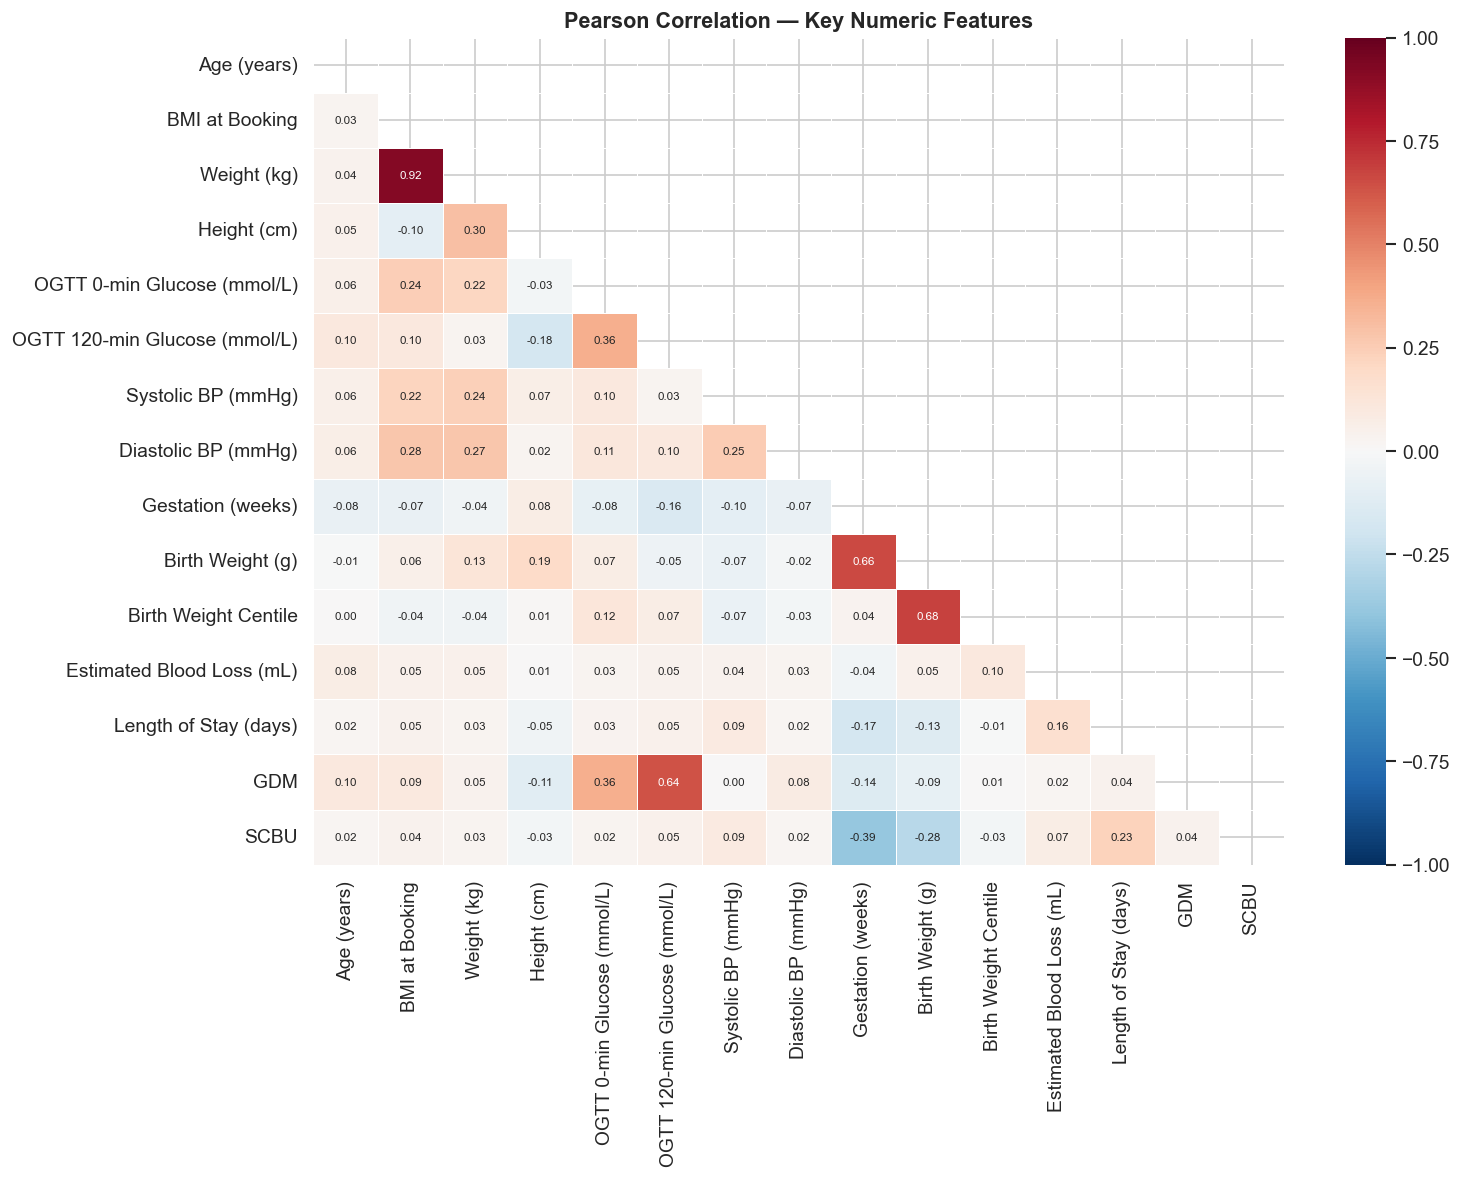

In [9]:
CORR_COLS = [
    'AgeAtStartOfSpell', 'Body Mass Index at Booking', 'WeightMeasured', 'Height',
    'Glucoselevel0minblood', 'Glucoselevel120minblood',
    'SystolicBloodPressureCuff', 'Diastolic Blood Pressure',
    'Gestation', 'BabyBirthWeight', 'BW Centile',
    'EstimatedTotalBloodLoss', 'LOS mother after delivery',
    'GDM', 'SCBU'
]

corr = df[CORR_COLS].corr()
corr.index   = [LABELS.get(c, c) for c in corr.index]
corr.columns = [LABELS.get(c, c) for c in corr.columns]

fig, ax = plt.subplots(figsize=(13, 10))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(
    corr, mask=mask, annot=True, fmt='.2f',
    cmap='RdBu_r', center=0, vmin=-1, vmax=1,
    linewidths=0.4, annot_kws={'size': 7},
    ax=ax
)
ax.set_title('Pearson Correlation — Key Numeric Features', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## 9. GDM Prevalence by Ethnicity & Obesity

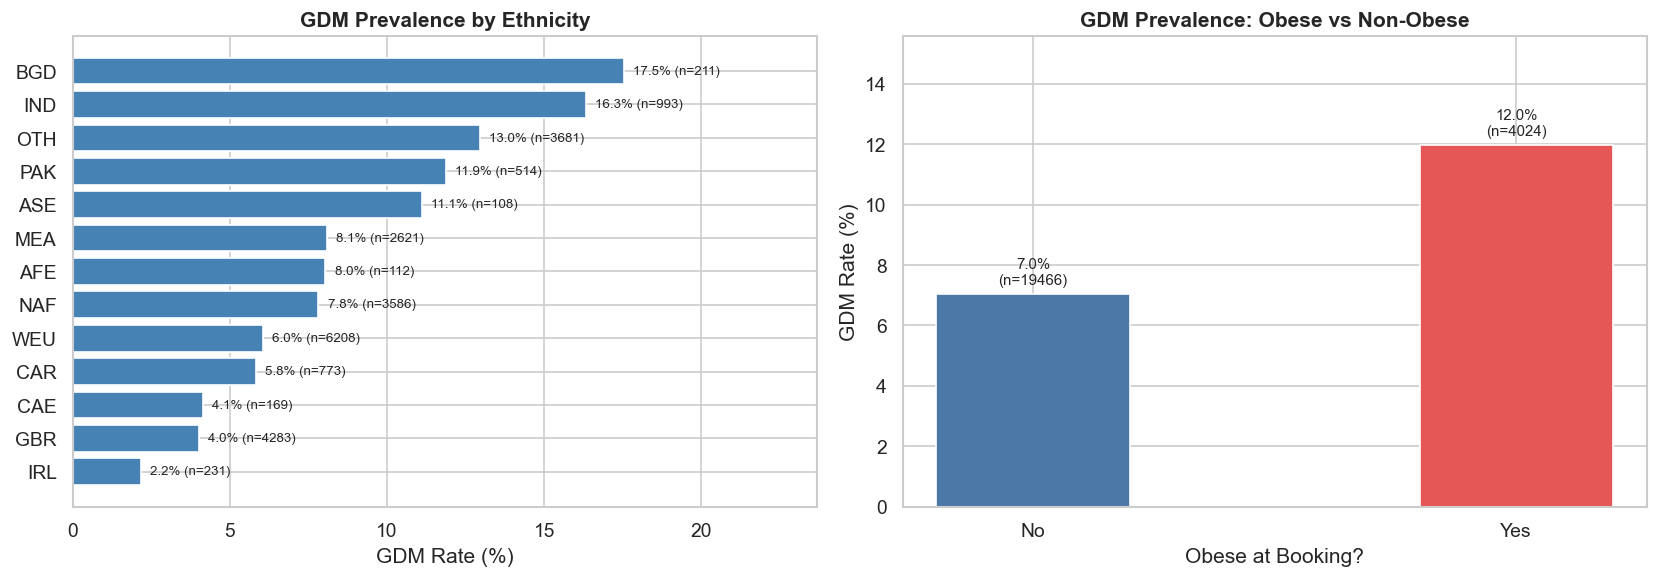

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- GDM rate by ethnicity ---
eth_gdm = (
    gdm_df.groupby('Ethnicity')['GDM']
    .agg(['mean', 'count'])
    .query('count >= 100')
    .sort_values('mean', ascending=True)
)
eth_gdm['mean_pct'] = eth_gdm['mean'] * 100
ax = axes[0]
bars = ax.barh(eth_gdm.index, eth_gdm['mean_pct'], color='steelblue', edgecolor='white')
for bar, (_, row) in zip(bars, eth_gdm.iterrows()):
    ax.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2,
            f"{row['mean_pct']:.1f}% (n={int(row['count'])})",
            va='center', fontsize=8)
ax.set_xlabel('GDM Rate (%)')
ax.set_title('GDM Prevalence by Ethnicity', fontweight='bold')
ax.set_xlim(0, eth_gdm['mean_pct'].max() * 1.35)

# --- GDM rate by Obesity ---
ax2 = axes[1]
obese_gdm = (
    gdm_df.dropna(subset=['Obese?'])
    .groupby('Obese?')['GDM']
    .agg(['mean', 'count'])
)
obese_gdm['mean_pct'] = obese_gdm['mean'] * 100
colors = ['#4c78a8', '#e45756']
bars2 = ax2.bar(obese_gdm.index, obese_gdm['mean_pct'], color=colors, edgecolor='white', width=0.4)
for bar, (_, row) in zip(bars2, obese_gdm.iterrows()):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
             f"{row['mean_pct']:.1f}%\n(n={int(row['count'])})",
             ha='center', fontsize=9)
ax2.set_xlabel('Obese at Booking?')
ax2.set_ylabel('GDM Rate (%)')
ax2.set_title('GDM Prevalence: Obese vs Non-Obese', fontweight='bold')
ax2.set_ylim(0, obese_gdm['mean_pct'].max() * 1.3)

plt.tight_layout()
plt.show()

## 10. APGAR Score Distributions

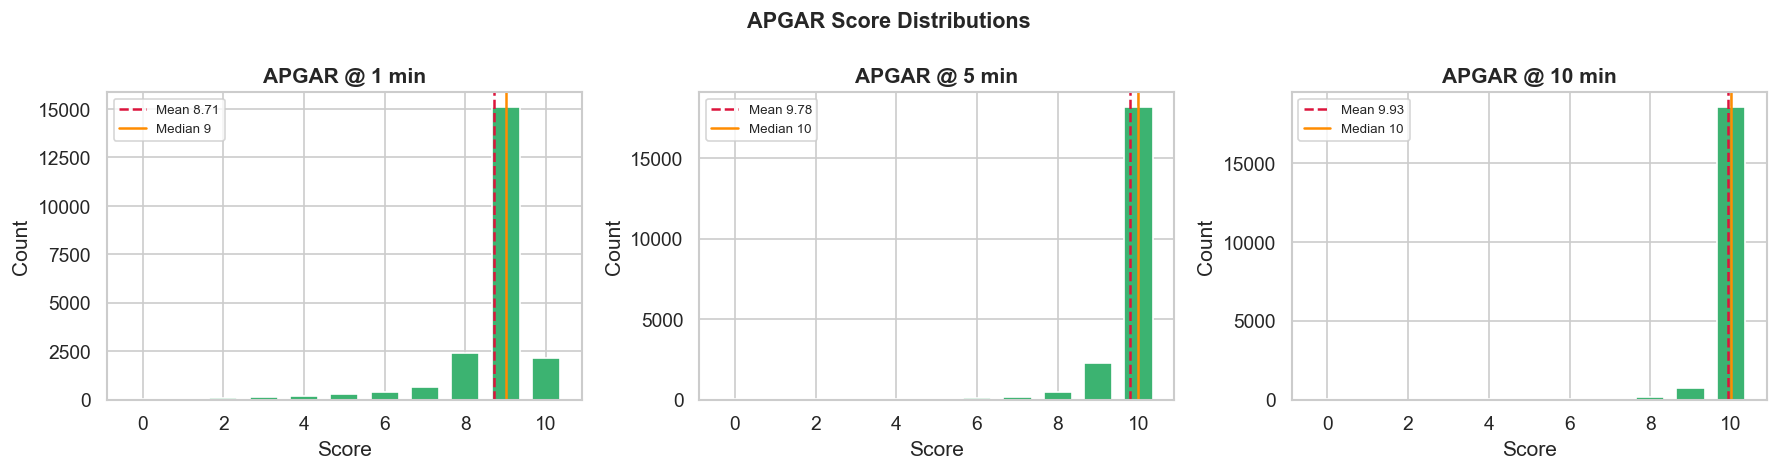

In [11]:
APGAR_COLS = ['TotalApgarScoreat1minutes', 'APGAR_Score_5', 'TotalApgarScoreat10minutes']
APGAR_LABELS = ['APGAR @ 1 min', 'APGAR @ 5 min', 'APGAR @ 10 min']

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col, label in zip(axes, APGAR_COLS, APGAR_LABELS):
    data = df[col].dropna()
    counts = data.value_counts().sort_index()
    ax.bar(counts.index, counts.values, color='mediumseagreen', edgecolor='white', width=0.7)
    ax.axvline(data.mean(),   color='crimson',    linestyle='--', linewidth=1.5, label=f'Mean {data.mean():.2f}')
    ax.axvline(data.median(), color='darkorange', linestyle='-',  linewidth=1.5, label=f'Median {data.median():.0f}')
    ax.set_title(label, fontweight='bold')
    ax.set_xlabel('Score')
    ax.set_ylabel('Count')
    ax.legend(fontsize=8)

fig.suptitle('APGAR Score Distributions', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()